# Lecture 7 Activity – Does where a voter lives catch what the surname misses?

QSS 20 · Modern Statistical Computing · Fall 2026

## The question

In lecture, the largest group for a voter's surname guessed the recorded race
right for 79.1 percent of Florida voters. For Black voters, it was right for
only 16.2 percent. Many Black Americans hold surnames that more white Americans hold,
such as WILLIAMS and JOHNSON.

The voter file also records where each voter lives: `county` and `VTD`, the
voting district. A Census table gives, for each district, the share of its
residents in each group.

> **Does a guess from the voter's district catch the Black voters that the
> surname guess misses, and what does it get wrong instead?**

### Reminders

- `voters`: one row per voter. `districts`: one row per voting district, with
  the shares `white`, `black`, `hispanic`, `api`, and `others` (from 0 to 1).
- A `VTD` number repeats across counties, so only the pair (`county`, `VTD`)
  identifies a district.
- Compare the two guesses on the **same voters**.
- In the starter cells, replace each `...` with code.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.max_rows', 8)

# Sharp figures on high-resolution screens, from lecture 6.
%config InlineBackend.figure_format = 'retina'

voters = pd.read_csv('../data/raw/FLVoters.csv', keep_default_na=False, na_values=['NA'])
names = pd.read_csv('../data/raw/names.csv', keep_default_na=False)
districts = pd.read_csv('../data/raw/FLCensusVTD.csv')

# The lecture's surname guess: the largest group for each surname.
pct_cols = ['pctwhite', 'pctblack', 'pctapi', 'pcthispanic', 'pctothers']
to_race = {'pctwhite': 'white', 'pctblack': 'black', 'pctapi': 'asian',
           'pcthispanic': 'hispanic', 'pctothers': 'other'}
names = names.assign(name_guess=names[pct_cols].idxmax(axis=1).map(to_race))

voters = voters.merge(names[['surname', 'name_guess']], on='surname',
                      how='left', validate='many_to_one')

# Check: 10,000 voters, and 8,806 of them have a surname guess.
len(voters), voters['name_guess'].notna().sum()

(10000, 8806)

## Task 1 · Join each voter to their district

First check that the pair (`county`, `VTD`) appears only once in
`districts`. Then merge `districts` onto `voters` with a left join on **both**
columns, with `validate` and `indicator=True`, as `with_district`.

How many rows does `with_district` have, and how many voters found their
district?

In [2]:
print('repeated (county, VTD) pairs:',
      districts.duplicated(subset=['county', 'VTD']).sum())

with_district = voters.merge(districts, on=['county', 'VTD'], how='left',
                             validate='many_to_one', indicator=True)
print('rows:', len(with_district))
with_district['_merge'].value_counts()

repeated (county, VTD) pairs: 0
rows: 10000


_merge
both          10000
left_only         0
right_only        0
Name: count, dtype: int64

No (`county`, `VTD`) pair repeats, so the pair is a key. The merge keeps
**10,000 rows**, one per voter, and every voter finds a district: 10,000 in
`both`, none `left_only`.

## Task 2 · A guess from the district

Guess each voter's race as the **largest group in their district**. Use
`idxmax(axis=1)` on the five share columns and rename the groups with `.map`,
so `api` becomes `asian` and `others` becomes `other`.

Then keep the voters with **both** a recorded race and a surname guess, as
`known`, and compute the share for whom the district guess is right. How does
it compare with the surname guess on the same voters?

In [3]:
district_cols = ['white', 'black', 'hispanic', 'api', 'others']
to_voter = {'white': 'white', 'black': 'black', 'hispanic': 'hispanic',
            'api': 'asian', 'others': 'other'}

with_district = with_district.assign(
    district_guess=with_district[district_cols].idxmax(axis=1).map(to_voter))

known = with_district.loc[with_district['race'].notna()
                          & with_district['name_guess'].notna()]
print('voters:', len(known))
print('surname guess right: ', round((known['name_guess'] == known['race']).mean(), 3))
print('district guess right:', round((known['district_guess'] == known['race']).mean(), 3))

voters: 8033
surname guess right:  0.791
district guess right: 0.77


On the same 8,033 voters, the district guess is right for **0.770** of them,
against **0.791** for the surname guess. Overall, the district does slightly
worse.

## Task 3 · ❓ Group by group

In lecture, the overall accuracy hid the
difference between groups. Build one table with one row
per recorded race and three named columns: `voters` (how many), `surname`
(share the surname guess gets right), and `district` (share the district
guess gets right). Then draw `surname` and `district` side by side as a
horizontal bar chart.

For which groups does the district do better, and for which does it do
worse?

In [4]:
by_group = (
    known
    .assign(name_right=known['name_guess'] == known['race'],
            district_right=known['district_guess'] == known['race'])
    .groupby('race')
    .agg(voters=('race', 'size'),
         surname=('name_right', 'mean'),
         district=('district_right', 'mean'))
)
by_group.round(3)

,voters,surname,district
race,,,
asian,140,0.564,0.000
black,1080,0.162,0.494
hispanic,1024,0.847,0.570
native,26,0.000,0.000
other,255,0.004,0.000
white,5508,0.950,0.921


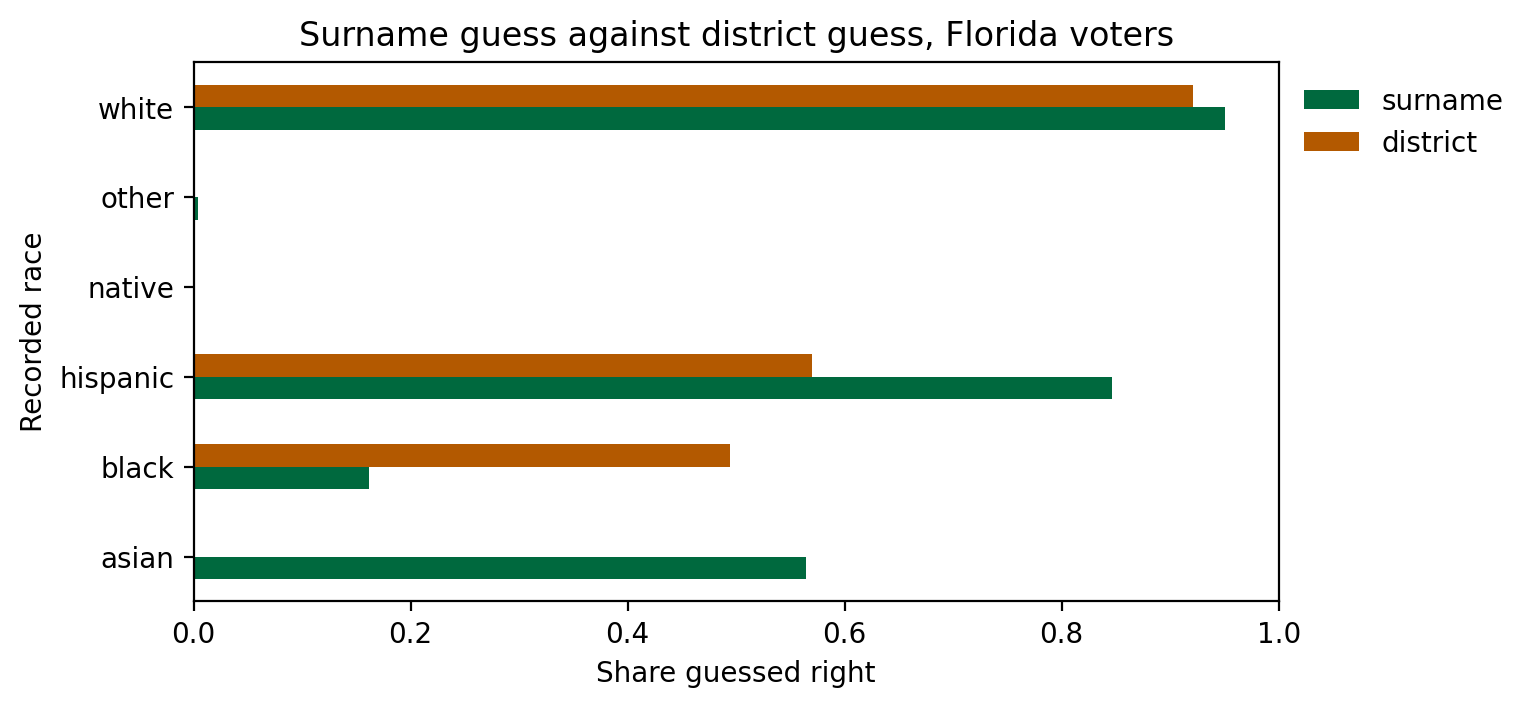

In [5]:
ax = by_group[['surname', 'district']].plot.barh(figsize=(7, 3.5),
                                                color=['#00693e', '#b35900'])
ax.set(xlabel='Share guessed right', ylabel='Recorded race', xlim=(0, 1),
       title='Surname guess against district guess, Florida voters')
ax.legend(loc='upper left', bbox_to_anchor=(1, 1), frameon=False);

The district guess catches many more **Black** voters: 0.494 against 0.162
for the surname. It does worse for **Hispanic** voters (0.570 against 0.847)
and for **Asian** voters (0.000 against 0.564), and slightly worse for white
voters (0.921 against 0.950). None of the 140 Asian voters lives in a
district where Asian residents are the largest group.

The two guesses fail for different people, so neither one is better for
everyone.

## Task 4 · What the guesses cannot tell you

Write two or three sentences. When can a district guess be right for a Black
voter, and when must it be wrong? What can neither guess establish about one
voter, and what does that mean for counting voters by race?

A district guess can be right for a Black voter only if the voter lives in a
district where Black residents are the largest group. It must be wrong for
every Black voter in a mostly white or mostly Hispanic district. It works only
as far as groups live in different places. It describes the district, and a
voter can differ from the district.

Neither guess establishes any one voter's race: each describes a name or a
place. Both make errors that differ by group, so a count built on either one
has a known bias. The surname undercounts Black voters; the district
undercounts Hispanic and Asian voters who live among other groups. Neither
guess can produce `native`, because neither Census table reports that group.

## If you finish early · Combine the two

A simple version of Bayesian Improved Surname Geocoding (BISG)
multiplies the two pieces of information. For each group,
compute a score:

> surname share × district share ÷ the group's national share

and guess the group with the largest score. Dividing by the national share
keeps a large group from winning everywhere. Compute the accuracy by race and
compare it with Task 3.

In [6]:
# National share of each group, over all people in the surname list.
national = (names[pct_cols].mul(names['count'], axis=0).sum()
            / names['count'].sum())

both = known.merge(names[['surname'] + pct_cols], on='surname',
                   how='left', validate='many_to_one')
pairs = {'white': ('pctwhite', 'white'), 'black': ('pctblack', 'black'),
         'hispanic': ('pcthispanic', 'hispanic'), 'asian': ('pctapi', 'api'),
         'other': ('pctothers', 'others')}
scores = pd.DataFrame({race: both[p] * both[d] / national[p]
                       for race, (p, d) in pairs.items()})
both = both.assign(combined_guess=scores.idxmax(axis=1))

(both.assign(right=both['combined_guess'] == both['race'])
     .groupby('race')['right'].mean()
     .round(3))

race
asian       0.564
black       0.674
hispanic    0.872
native      0.000
other       0.000
white       0.924
Name: right, dtype: float64

Combining the two raises Black accuracy to **0.674** and Hispanic accuracy to
**0.872**, above both single guesses. For white voters it sits between them
(0.924), and for Asian voters it matches the surname guess (0.564). It still
misses about a third of Black voters.

## What to take from this

- A two-column key needs both columns in `on=`; check that the pair repeats
  nowhere in the lookup table before you merge.
- Compare two methods on the same rows, and report the result group by group.
- A guess from a place describes the place. It is wrong for voters whose group
  differs from the largest group where they live.